<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_depolarizing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
drive.mount("/content/drive")


Mounted at /content/drive


# Parametes

In [ ]:
Gamma = 0.25
delta_t = 0.5
g = np.sqrt(Gamma/delta_t)
omega = 1
N = int(30/delta_t)
nshots = 1024


# Load results from Linblad equation

In [ ]:
file_path = (
    '/content/drive/MyDrive/'
    'cont_solution_dt_0.5_g_0.71_omegas_1.txt'
)

data_cont = np.loadtxt(file_path, comments='#')

t_cont = data_cont[:, 0]
sx_cont = data_cont[:, 1]
sy_cont = data_cont[:, 2]
sz_cont = data_cont[:, 3]

# Create Noise model

# Refresh Ancilla

### Noise - flip

In [ ]:
def sz_2_circuit(simulator_aer_noise):
  sz_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)
      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_noiseflip1.append(-valor)
  return sz_2_noiseflip1

In [ ]:
def sx_2_circuit(simulator_aer_noise):
  sx_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)


      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_noiseflip1.append(valor)
  return sx_2_noiseflip1

In [ ]:
def sy_2_circuit(simulator_aer_noise):
  sy_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_noiseflip1.append(-valor)
  return sy_2_noiseflip1

## Plot and save data

### Different l_depol

> Añadir blockquote



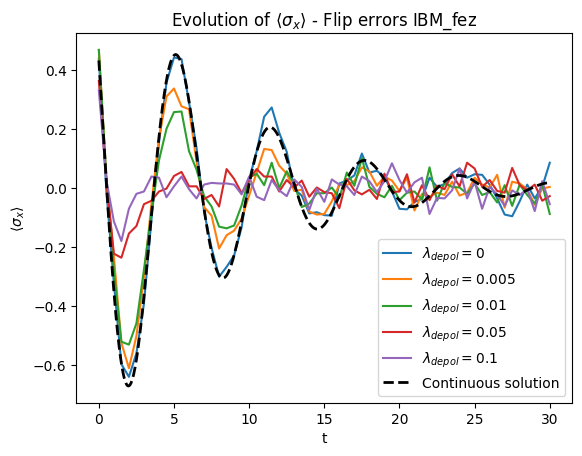

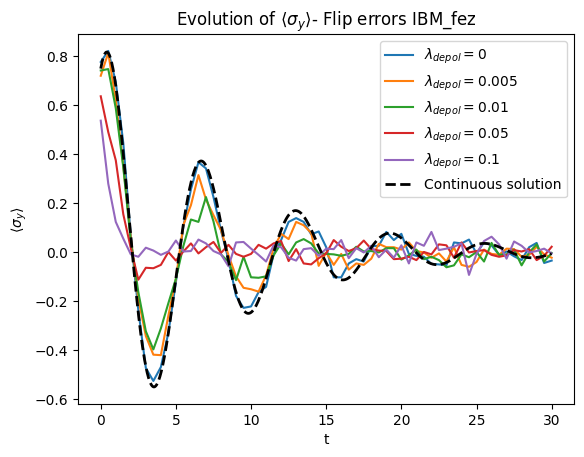

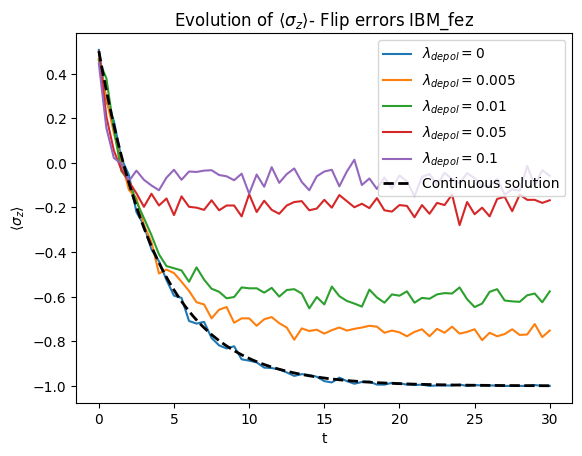

In [ ]:
simualtor_aer = AerSimulator()

time = np.arange(N+1) * delta_t



fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

l_depol_list = [0,0.005,0.01, 0.05, 0.1]

for l_depol in l_depol_list:

  # QuantumError objects
  error_depol = depolarizing_error(l_depol, 1)

  noise_depol = NoiseModel()
  noise_depol.add_all_qubit_quantum_error(error_depol, ["sdg", "ry", "rz","h"])
  simulator_aer_noise = AerSimulator(noise_model=noise_depol)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  np.savetxt(
  f"/content/drive/MyDrive/qiskit_noisedepol_sxsysz_ns1024_ldep_{l_depol}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )

  ax_x.plot(time, sx_2, label=rf'$\lambda_{{depol}}={l_depol}$')
  ax_y.plot(time, sy_2, label=rf'$\lambda_{{depol}}={l_depol}$')
  ax_z.plot(time, sz_2, label=rf'$\lambda_{{depol}}={l_depol}$')

ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)
# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ - Flip errors IBM_fez')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$- Flip errors IBM_fez')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$- Flip errors IBM_fez')
ax_z.legend()

plt.show()


### fez p_depol

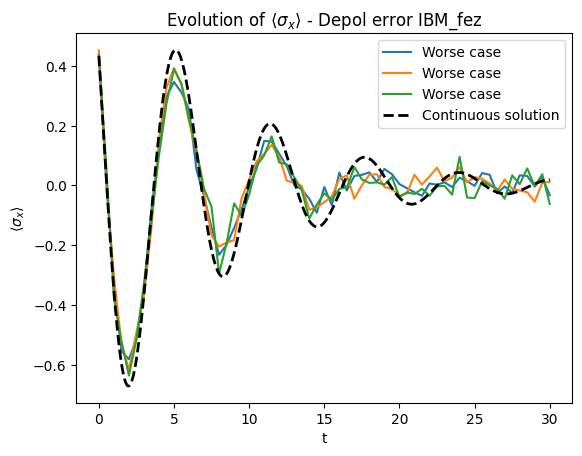

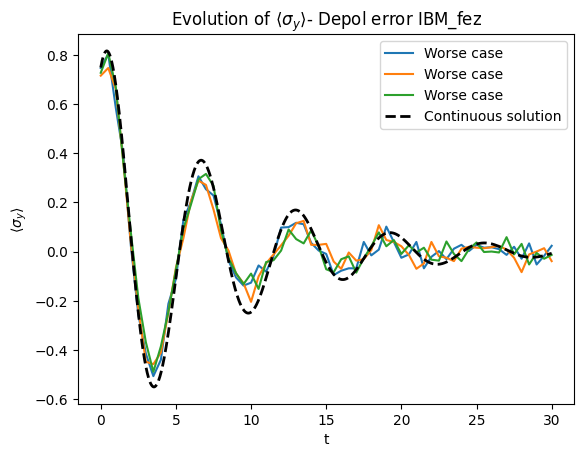

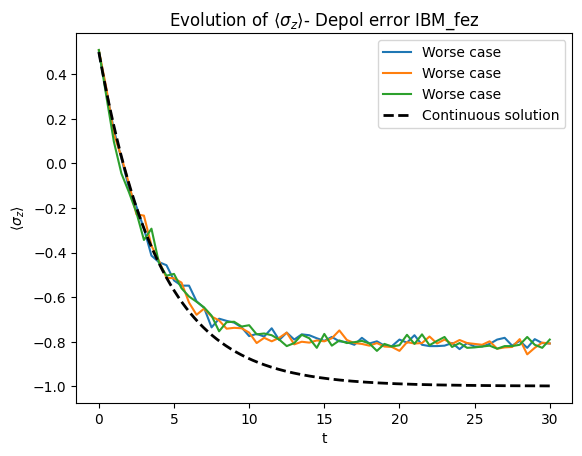

In [ ]:
simualtor_aer = AerSimulator()

time = np.arange(N+1) * delta_t



fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

l_depol_best= 0.0000978*3/4
l_depol_worse = 0.00496*3/4
l_depol_median = 0.0003141*3/4

l_depol_list = [l_depol_best,l_depol_worse, l_depol_median]

for l_depol in l_depol_list:

  # QuantumError objects
  error_depol = depolarizing_error(l_depol, 1)

  noise_depol = NoiseModel()
  noise_depol.add_all_qubit_quantum_error(error_depol, ["sdg", "ry", "rz","h"])
  simulator_aer_noise = AerSimulator(noise_model=noise_depol)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  if l_depol == l_depol_worse:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisedepol_sxsysz_ns1024_fezworsecase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Worse case')
    ax_y.plot(time, sy_2, label=rf'Worse case')
    ax_z.plot(time, sz_2, label=rf'Worse case')

  if l_depol == l_depol_best:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisedepol_sxsysz_ns1024_fezbestcase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Best case')
    ax_y.plot(time, sy_2, label=rf'Best case')
    ax_z.plot(time, sz_2, label=rf'Best case')

  if l_depol == l_depol_median:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisedepol_sxsysz_ns1024_fezmedian.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Median')
    ax_y.plot(time, sy_2, label=rf'Median')
    ax_z.plot(time, sz_2, label=rf'Median')


ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)
# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ - Depol error IBM_fez')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$- Depol error IBM_fez')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$- Depol error IBM_fez')
ax_z.legend()

plt.show()


### No noise

In [ ]:
def sz_2_nonoise_circuit(simulator_aer):
  sz_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)

      job = simualtor_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [ ]:
def sx_2_nonoise_circuit(simulator_aer):
  sx_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)


      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [ ]:
def sy_2_nonoise_circuit(simulator_aer):
  sy_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_nonoise.append(-valor)
  return sy_2_nonoise

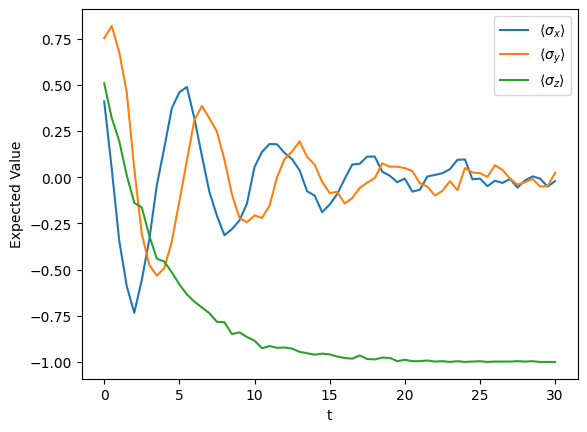

In [ ]:
simulator_aer = AerSimulator()
sx_2_nonoise = sx_2_nonoise_circuit(simulator_aer)
sy_2_nonoise= sy_2_nonoise_circuit(simulator_aer)
sz_2_nonoise= sz_2_nonoise_circuit(simulator_aer)

time = np.arange(N+1) * delta_t
plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns4096.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
